In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
DATA_PATH = Path("../Data/Cleaned/Nepal_Online_Payment_System.csv")

df = pd.read_csv(DATA_PATH)
df["period_end"] = pd.to_datetime(df["period_end"])

In [2]:
df.shape

(645, 11)

### How much transaction activity is happening each month across all payment instruments?

In [3]:
monthly_totals = (
    df.groupby("period_end")
    .agg(
        total_txn_count=("txn_count", "sum"),
        total_txn_amount_npr_million=("txn_amount_npr_million", "sum")
    )
    .sort_index()
)

display(monthly_totals.round(2))

,total_txn_count,total_txn_amount_npr_million
period_end,,
2023-07-01,100916114,5156481
2023-08-01,90886739,3985007
2023-09-01,95836096,3229087
2023-10-01,96256655,4073231
2023-11-01,82548409,3206725
2023-12-01,89227481,3733385
2024-01-01,93750989,3883287
2024-02-01,99192199,4051320
2024-03-01,96053423,4684595


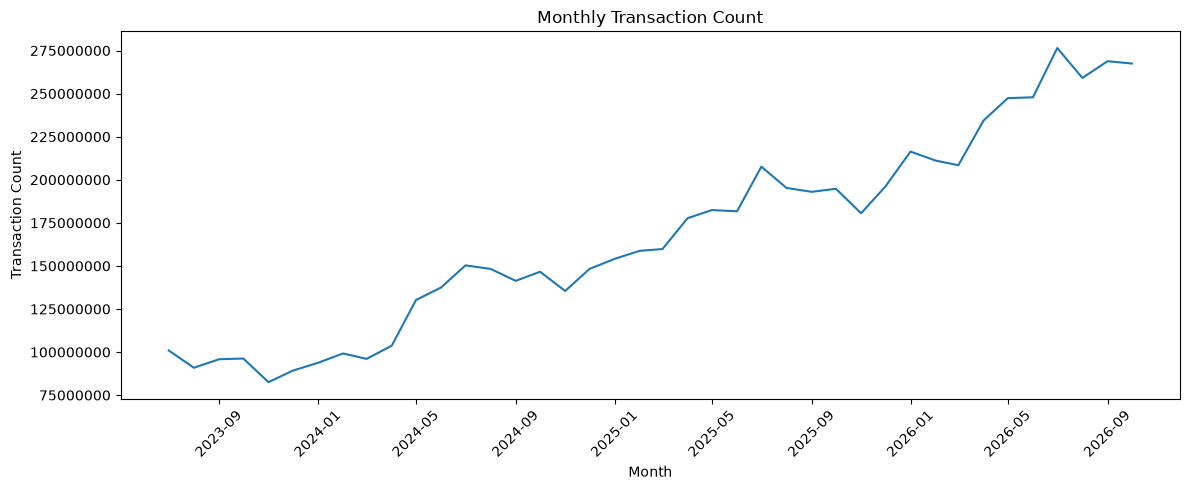

In [4]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_totals.index,
    monthly_totals["total_txn_count"]
)

plt.title("Monthly Transaction Count")
plt.xlabel("Month")
plt.ylabel("Transaction Count")
plt.xticks(rotation=45)
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

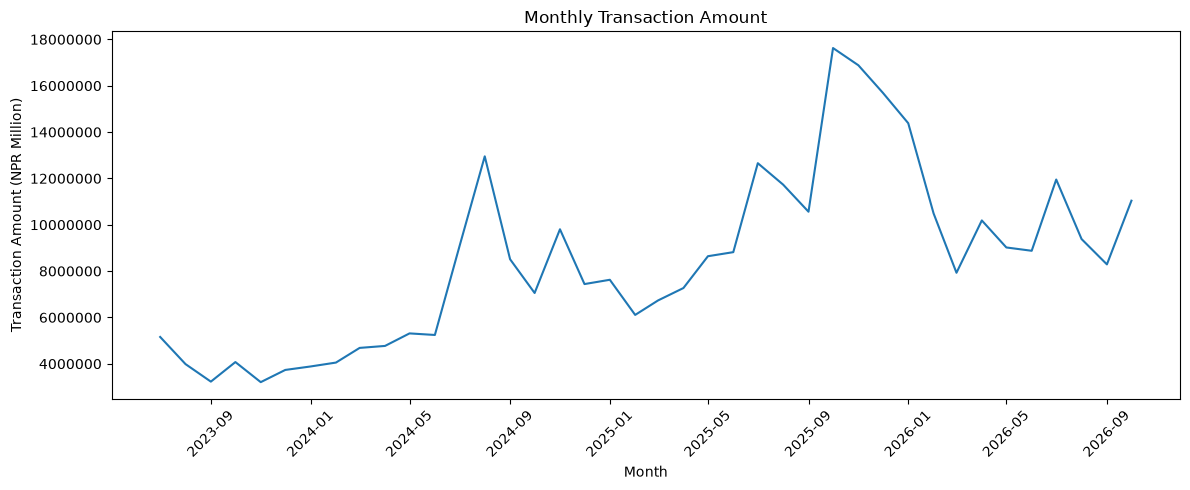

In [5]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_totals.index,
    monthly_totals["total_txn_amount_npr_million"]
)

plt.title("Monthly Transaction Amount")
plt.xlabel("Month")
plt.ylabel("Transaction Amount (NPR Million)")
plt.xticks(rotation=45)
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

In [6]:
monthly_totals["avg_transaction_value_npr"] = (
    monthly_totals["total_txn_amount_npr_million"] * 1_000_000
    / monthly_totals["total_txn_count"]
)

display(monthly_totals.round(2))

,total_txn_count,total_txn_amount_npr_million,avg_transaction_value_npr
period_end,,,
2023-07-01,100916114,5156481,51096.71
2023-08-01,90886739,3985007,43845.86
2023-09-01,95836096,3229087,33693.85
2023-10-01,96256655,4073231,42316.36
2023-11-01,82548409,3206725,38846.60
2023-12-01,89227481,3733385,41841.20
2024-01-01,93750989,3883287,41421.29
2024-02-01,99192199,4051320,40843.13
2024-03-01,96053423,4684595,48770.72


### Observations:
1. Monthly transaction count increased substantially over the reporting period.
2. Monthly transaction amount also increased, although not consistently.
3. Average transaction value fluctuated, rather than increasing continuously.

### How much did transaction activity increase or decrease compared with the previous month?

In [7]:
monthly_totals["count_mom_growth_pct"] = (
    monthly_totals["total_txn_count"].pct_change() * 100
)

monthly_totals["amount_mom_growth_pct"] = (
    monthly_totals["total_txn_amount_npr_million"].pct_change() * 100
)

display(monthly_totals.round(2))

,total_txn_count,total_txn_amount_npr_million,avg_transaction_value_npr,count_mom_growth_pct,amount_mom_growth_pct
period_end,,,,,
2023-07-01,100916114,5156481,51096.71,NaN,NaN
2023-08-01,90886739,3985007,43845.86,-9.94,-22.72
2023-09-01,95836096,3229087,33693.85,5.45,-18.97
2023-10-01,96256655,4073231,42316.36,0.44,26.14
2023-11-01,82548409,3206725,38846.60,-14.24,-21.27
2023-12-01,89227481,3733385,41841.20,8.09,16.42
2024-01-01,93750989,3883287,41421.29,5.07,4.02
2024-02-01,99192199,4051320,40843.13,5.80,4.33
2024-03-01,96053423,4684595,48770.72,-3.16,15.63


In [49]:
months_per_instrument = df.groupby("instrument")["period_end"].nunique()
always_reported = months_per_instrument[months_per_instrument == 40].index

like_for_like = (
    df[df["instrument"].isin(always_reported)]
    .groupby("period_end")["txn_count"]
    .sum()
)

like_for_like_growth = (like_for_like.pct_change() * 100).round(2)
like_for_like_growth.sort_values()

period_end
2023-11-01   -14.24
2024-11-01    -6.69
2025-11-01    -6.32
2024-09-01    -5.50
2026-08-01    -5.20
2025-08-01    -4.86
2024-03-01    -3.16
2026-10-01    -2.68
2026-02-01    -2.46
2026-03-01    -1.37
2024-08-01    -1.24
2025-09-01    -1.23
2025-06-01    -0.53
2025-10-01    -0.09
2025-03-01     0.30
2023-10-01     0.44
2026-06-01     0.47
2026-09-01     2.71
2025-05-01     2.87
2025-02-01     3.17
2024-10-01     3.39
2025-01-01     3.62
2023-08-01     3.93
2024-07-01     4.35
2024-01-01     5.07
2023-09-01     5.45
2024-06-01     5.79
2024-02-01     5.80
2026-05-01     6.12
2024-04-01     7.95
2023-12-01     8.09
2025-12-01     8.56
2024-12-01     9.66
2026-01-01    10.22
2026-07-01    10.85
2025-04-01    11.43
2026-04-01    12.17
2025-07-01    13.33
2024-05-01    13.93
2023-07-01      NaN
Name: txn_count, dtype: float64

### Key observations
Transaction count growth (like-for-like, using the 14 instruments reported in all 40 months)
- Highest growth: +13.93% in May 2024. The unadjusted total showed +25.61%, but about half of that came from Faster Payment Systems reporting again.
- Largest decline: -14.24% in November 2023. The three largest declines are all in November (Nov 2023: -14.24%, Nov 2024: -6.69%, Nov 2025: -6.32%), which points to a festival-season dip.
- The -9.94% fall in August 2023 in the total was caused by instruments missing from the data. Like-for-like, August 2023 grew +3.93%.
- Transaction count generally shows an upward trend over the longer period.

Transaction amount growth (all instruments, not adjusted)
- Highest growth: +72.78% in July 2024.
- Largest decline: -34.29% in September 2024.
- Transaction amount fluctuates much more than transaction count. It is dominated by RTGS (about 73% of total value), and a like-for-like check was not done for amount.

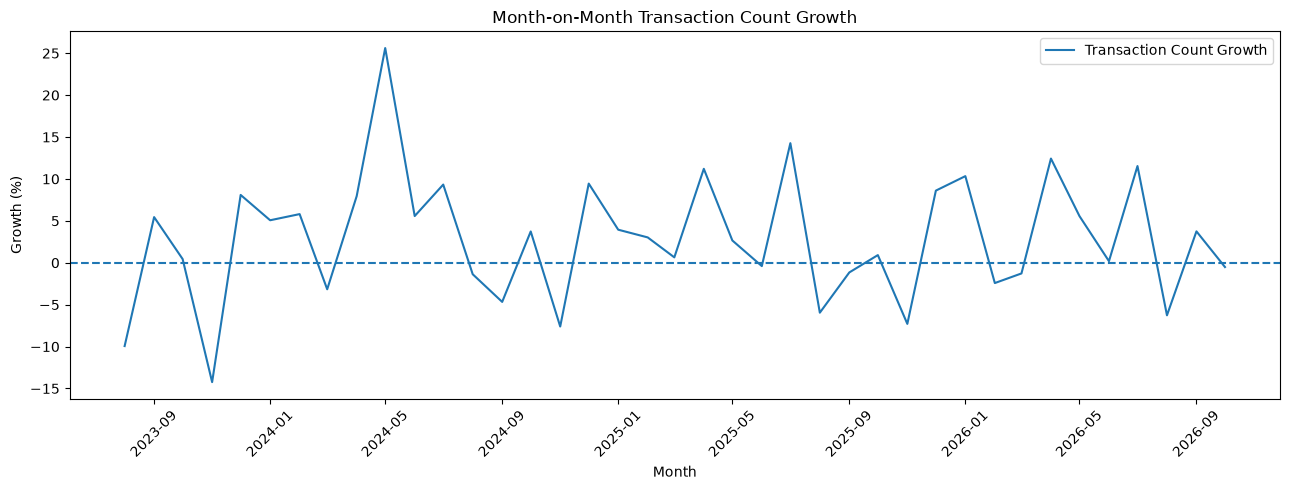

In [8]:
plt.figure(figsize=(13, 5))

plt.plot(
    monthly_totals.index,
    monthly_totals["count_mom_growth_pct"],
    label="Transaction Count Growth"
)

plt.axhline(y=0, linestyle="--")

plt.title("Month-on-Month Transaction Count Growth")
plt.xlabel("Month")
plt.ylabel("Growth (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

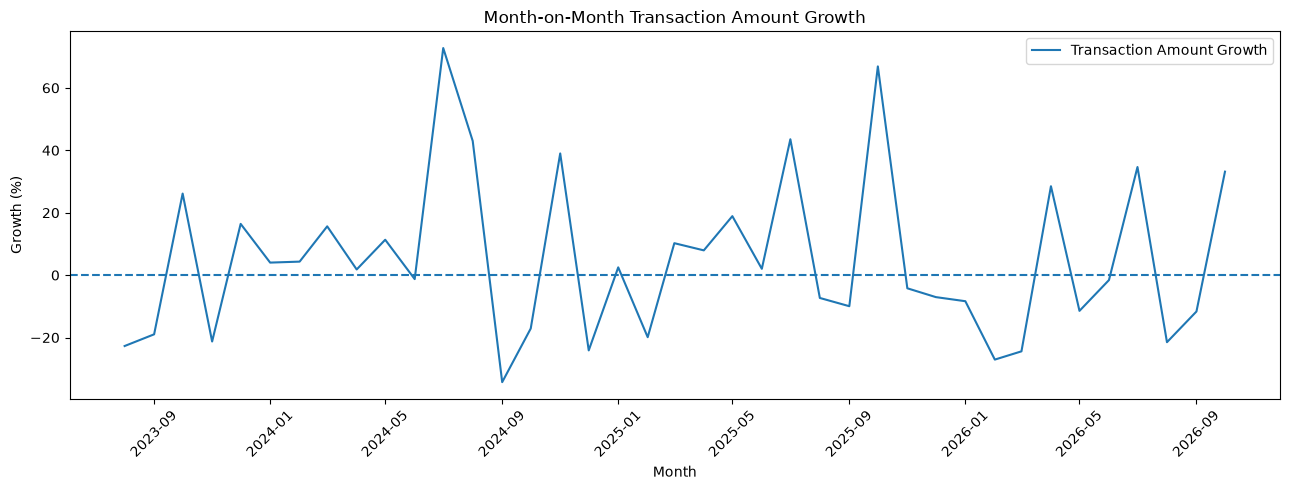

In [9]:
plt.figure(figsize=(13, 5))

plt.plot(
    monthly_totals.index,
    monthly_totals["amount_mom_growth_pct"],
    label="Transaction Amount Growth"
)

plt.axhline(y=0, linestyle="--")

plt.title("Month-on-Month Transaction Amount Growth")
plt.xlabel("Month")
plt.ylabel("Growth (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
nepali_month_order = [
    "Baisakh", "Jestha", "Asar", "Saun",
    "Bhadau", "Asoj", "Kartik", "Mangsir",
    "Pus", "Magh", "Falgun", "Chaitra"
]

df["bs_month"] = pd.Categorical(
    df["bs_month"],
    categories=nepali_month_order,
    ordered=True
)

bs_calendar = (
    df[["bs_year", "bs_month"]]
    .drop_duplicates()
    .sort_values(["bs_year", "bs_month"])
    .reset_index(drop=True)
)

bs_calendar

,bs_year,bs_month
0,2080,Asar
1,2080,Saun
2,2080,Bhadau
3,2080,Asoj
4,2080,Kartik
5,2080,Mangsir
6,2080,Pus
7,2080,Magh
8,2080,Falgun
9,2080,Chaitra


In [11]:
bs_monthly_totals = (
    df.groupby(["bs_year", "bs_month"], observed=True)
    .agg(
        total_txn_count=("txn_count", "sum"),
        total_txn_amount_npr_million=("txn_amount_npr_million", "sum")
    )
    .reset_index()
    .sort_values(["bs_year", "bs_month"])
)

bs_monthly_totals.head(15)

,bs_year,bs_month,total_txn_count,total_txn_amount_npr_million
0,2080,Asar,100916114,5156481
1,2080,Saun,90886739,3985007
2,2080,Bhadau,95836096,3229087
3,2080,Asoj,96256655,4073231
4,2080,Kartik,82548409,3206725
5,2080,Mangsir,89227481,3733385
6,2080,Pus,93750989,3883287
7,2080,Magh,99192199,4051320
8,2080,Falgun,96053423,4684595
9,2080,Chaitra,103685697,4769436


In [12]:
bs_monthly_totals["avg_transaction_value_npr"] = (
    bs_monthly_totals["total_txn_amount_npr_million"] * 1_000_000
    / bs_monthly_totals["total_txn_count"]
)

bs_monthly_totals.head(15)

,bs_year,bs_month,total_txn_count,total_txn_amount_npr_million,avg_transaction_value_npr
0,2080,Asar,100916114,5156481,51096.705923
1,2080,Saun,90886739,3985007,43845.857425
2,2080,Bhadau,95836096,3229087,33693.849549
3,2080,Asoj,96256655,4073231,42316.357243
4,2080,Kartik,82548409,3206725,38846.599696
5,2080,Mangsir,89227481,3733385,41841.201367
6,2080,Pus,93750989,3883287,41421.291033
7,2080,Magh,99192199,4051320,40843.131222
8,2080,Falgun,96053423,4684595,48770.724183
9,2080,Chaitra,103685697,4769436,45998.977082


### YoY growth for transaction count:

In [13]:
bs_monthly_totals["txn_count_yoy_growth_pct"] = (
    bs_monthly_totals
    .groupby("bs_month")["total_txn_count"]
    .pct_change() * 100
)

### YoY growth for transaction amount:

In [14]:
bs_monthly_totals["txn_amount_yoy_growth_pct"] = (
    bs_monthly_totals
    .groupby("bs_month")["total_txn_amount_npr_million"]
    .pct_change() * 100
)

In [15]:
bs_monthly_totals[
    [
        "bs_year",
        "bs_month",
        "txn_count_yoy_growth_pct",
        "txn_amount_yoy_growth_pct"
    ]
]

,bs_year,bs_month,txn_count_yoy_growth_pct,txn_amount_yoy_growth_pct
0,2080,Asar,NaN,NaN
1,2080,Saun,NaN,NaN
2,2080,Bhadau,NaN,NaN
3,2080,Asoj,NaN,NaN
4,2080,Kartik,NaN,NaN
5,2080,Mangsir,NaN,NaN
6,2080,Pus,NaN,NaN
7,2080,Magh,NaN,NaN
8,2080,Falgun,NaN,NaN
9,2080,Chaitra,NaN,NaN


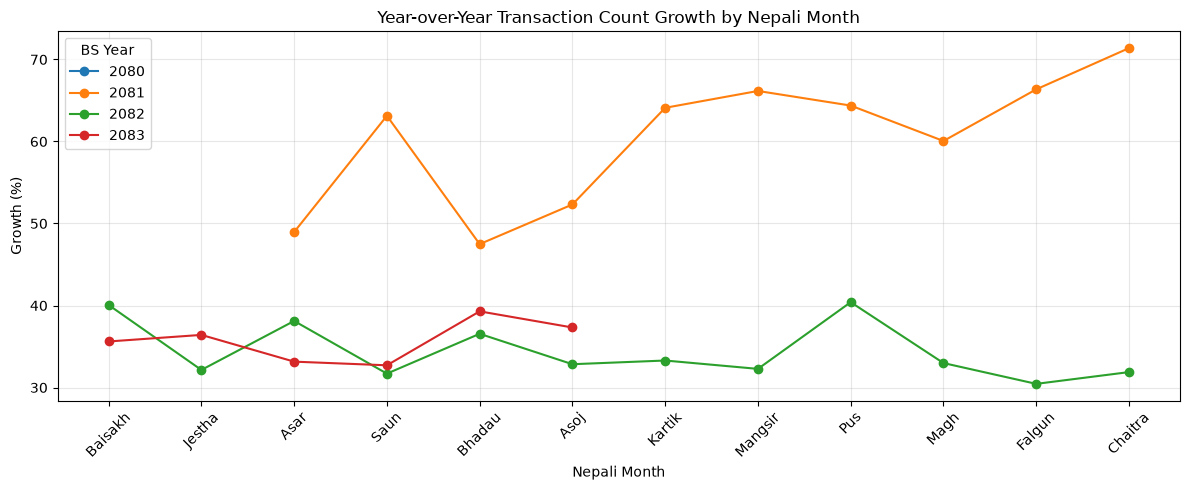

In [16]:
nepali_month_order = [
    "Baisakh", "Jestha", "Asar", "Saun",
    "Bhadau", "Asoj", "Kartik", "Mangsir",
    "Pus", "Magh", "Falgun", "Chaitra"
]

plt.figure(figsize=(12, 5))

for year, group in bs_monthly_totals.groupby("bs_year"):
    group = group.set_index("bs_month").reindex(nepali_month_order)

    plt.plot(
        nepali_month_order,
        group["txn_count_yoy_growth_pct"],
        marker="o",
        label=str(year)
    )

plt.title("Year-over-Year Transaction Count Growth by Nepali Month")
plt.xlabel("Nepali Month")
plt.ylabel("Growth (%)")
plt.legend(title="BS Year")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

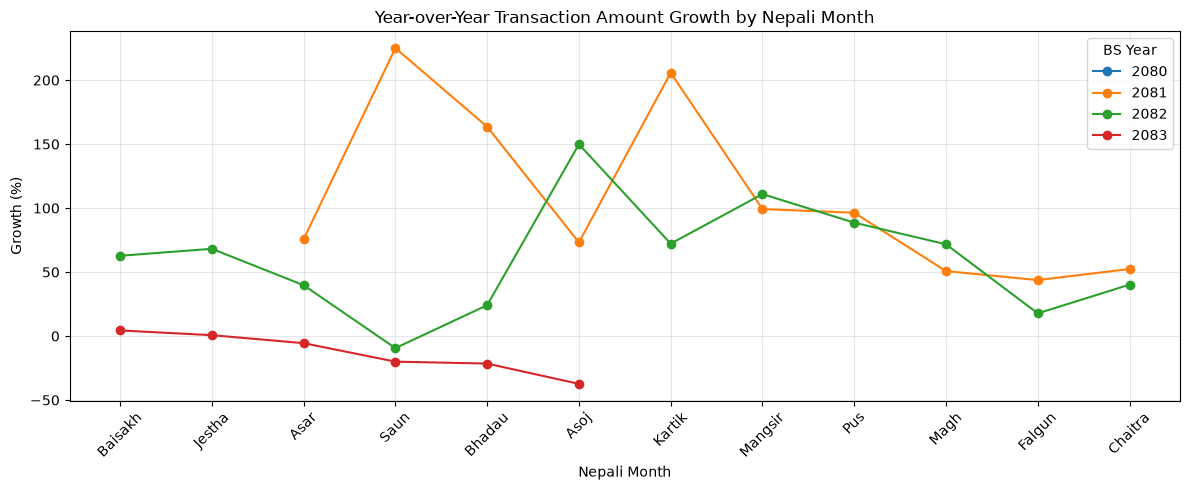

In [17]:
# Transaction Amount YoY Growth
plt.figure(figsize=(12, 5))

for year, group in bs_monthly_totals.groupby("bs_year"):
    group = group.set_index("bs_month").reindex(nepali_month_order)

    plt.plot(
        nepali_month_order,
        group["txn_amount_yoy_growth_pct"],
        marker="o",
        label=str(year)
    )

plt.title("Year-over-Year Transaction Amount Growth by Nepali Month")
plt.xlabel("Nepali Month")
plt.ylabel("Growth (%)")
plt.legend(title="BS Year")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### overall highest and lowest monthly transaction count and transaction amount

In [18]:
# Highest and lowest transaction count
highest_txn_count = bs_monthly_totals.loc[
    bs_monthly_totals["total_txn_count"].idxmax()
]

lowest_txn_count = bs_monthly_totals.loc[
    bs_monthly_totals["total_txn_count"].idxmin()
]

# Highest and lowest transaction amount
highest_txn_amount = bs_monthly_totals.loc[
    bs_monthly_totals["total_txn_amount_npr_million"].idxmax()
]

lowest_txn_amount = bs_monthly_totals.loc[
    bs_monthly_totals["total_txn_amount_npr_million"].idxmin()
]

print("Highest Transaction Count:")
print(highest_txn_count[["bs_year", "bs_month", "total_txn_count"]])

print("\nLowest Transaction Count:")
print(lowest_txn_count[["bs_year", "bs_month", "total_txn_count"]])

print("\nHighest Transaction Amount:")
print(highest_txn_amount[["bs_year", "bs_month", "total_txn_amount_npr_million"]])

print("\nLowest Transaction Amount:")
print(lowest_txn_amount[["bs_year", "bs_month", "total_txn_amount_npr_million"]])

Highest Transaction Count:
bs_year                 2083
bs_month                Asar
total_txn_count    276461473
Name: 36, dtype: object

Lowest Transaction Count:
bs_year                2080
bs_month             Kartik
total_txn_count    82548409
Name: 4, dtype: object

Highest Transaction Amount:
bs_year                             2082
bs_month                            Asoj
total_txn_amount_npr_million    17625574
Name: 27, dtype: object

Lowest Transaction Amount:
bs_year                            2080
bs_month                         Kartik
total_txn_amount_npr_million    3206725
Name: 4, dtype: object


### Identify the highest and lowest growth months

In [19]:
# Highest and lowest transaction count growth
highest_count_growth = bs_monthly_totals.loc[
    bs_monthly_totals["txn_count_yoy_growth_pct"].idxmax()
]

lowest_count_growth = bs_monthly_totals.loc[
    bs_monthly_totals["txn_count_yoy_growth_pct"].idxmin()
]

# Highest and lowest transaction amount growth
highest_amount_growth = bs_monthly_totals.loc[
    bs_monthly_totals["txn_amount_yoy_growth_pct"].idxmax()
]

lowest_amount_growth = bs_monthly_totals.loc[
    bs_monthly_totals["txn_amount_yoy_growth_pct"].idxmin()
]

print("Highest Transaction Count Growth:")
print(highest_count_growth[["bs_year", "bs_month", "txn_count_yoy_growth_pct"]])

print("\nLowest Transaction Count Growth:")
print(lowest_count_growth[["bs_year", "bs_month", "txn_count_yoy_growth_pct"]])

print("\nHighest Transaction Amount Growth:")
print(highest_amount_growth[["bs_year", "bs_month", "txn_amount_yoy_growth_pct"]])

print("\nLowest Transaction Amount Growth:")
print(lowest_amount_growth[["bs_year", "bs_month", "txn_amount_yoy_growth_pct"]])

Highest Transaction Count Growth:
bs_year                          2081
bs_month                      Chaitra
txn_count_yoy_growth_pct    71.383927
Name: 21, dtype: object

Lowest Transaction Count Growth:
bs_year                          2082
bs_month                       Falgun
txn_count_yoy_growth_pct    30.446204
Name: 32, dtype: object

Highest Transaction Amount Growth:
bs_year                            2081
bs_month                           Saun
txn_amount_yoy_growth_pct    225.017171
Name: 13, dtype: object

Lowest Transaction Amount Growth:
bs_year                           2083
bs_month                          Asoj
txn_amount_yoy_growth_pct   -37.377285
Name: 39, dtype: object


### Aggregate by BS year

In [20]:
bs_year_summary = (
    bs_monthly_totals
    .groupby("bs_year")
    .agg(
        total_txn_count=("total_txn_count", "sum"),
        total_txn_amount_npr_million=("total_txn_amount_npr_million", "sum"),
        avg_monthly_txn_count=("total_txn_count", "mean"),
        avg_monthly_txn_amount_npr_million=("total_txn_amount_npr_million", "mean"),
        months_reported=("bs_month", "count")
    )
    .reset_index()
)

bs_year_summary

,bs_year,total_txn_count,total_txn_amount_npr_million,avg_monthly_txn_count,avg_monthly_txn_amount_npr_million,months_reported
0,2080,948353802,40772554,9.483538e+07,4.077255e+06,10
1,2081,1788393065,93103606,1.490328e+08,7.758634e+06,12
2,2082,2401763369,145586744,2.001469e+08,1.213223e+07,12
3,2083,1567142360,58554518,2.611904e+08,9.759086e+06,6


### BS Year-over-Year Growth

In [21]:
bs_year_summary["avg_monthly_count_yoy_pct"] = (
    bs_year_summary["avg_monthly_txn_count"].pct_change() * 100
)
bs_year_summary["avg_monthly_amount_yoy_pct"] = (
    bs_year_summary["avg_monthly_txn_amount_npr_million"].pct_change() * 100
)

bs_year_summary

,bs_year,total_txn_count,total_txn_amount_npr_million,avg_monthly_txn_count,avg_monthly_txn_amount_npr_million,months_reported,avg_monthly_count_yoy_pct,avg_monthly_amount_yoy_pct
0,2080,948353802,40772554,9.483538e+07,4.077255e+06,10,NaN,NaN
1,2081,1788393065,93103606,1.490328e+08,7.758634e+06,12,57.148899,90.290602
2,2082,2401763369,145586744,2.001469e+08,1.213223e+07,12,34.297287,56.370682
3,2083,1567142360,58554518,2.611904e+08,9.759086e+06,6,30.499314,-19.560646


### BS Year-over-Year Growth (average per month)

**Why average per month:** The years do not have the same number of months in the dataset (BS 2080 has 10, BS 2081 and 2082 have 12, BS 2083 has 6). Comparing yearly totals would make 2083 look like a big fall, so growth is calculated on the **average monthly** values.

**Transaction count (average per month)**
- 2081: +57.1% vs 2080
- 2082: +34.3% vs 2081
- 2083: +30.5% vs 2082
- Volume keeps growing every year, but the pace is slowing.

**Transaction amount (average per month)**
- 2081: +90.3% vs 2080
- 2082: +56.4% vs 2081
- 2083: -19.6% vs 2082
- The 2083 fall is mainly driven by RTGS, which dominates value and moves a lot from month to month.

**Notes**
- BS 2080 covers Asar to Chaitra only, and BS 2083 covers Baisakh to Asoj only, so both are partial years.
- Because the months covered are different, the 2083 comparison is not perfectly like-for-like, so treat it as indicative.

### Which Nepali months generally have higher/lower transaction activity?

In [22]:
bs_month_seasonality = (
    bs_monthly_totals
    .groupby("bs_month", observed=True)
    .agg(
        avg_txn_count=("total_txn_count", "mean"),
        avg_txn_amount_npr_million=("total_txn_amount_npr_million", "mean"),
        years_available=("bs_year", "nunique")
    )
    .reindex(nepali_month_order)
    .reset_index()
)

bs_month_seasonality

,bs_month,avg_txn_count,avg_txn_amount_npr_million,years_available
0,Baisakh,1.866887e+08,7.656927e+06,3
1,Jestha,1.890214e+08,7.644932e+06,3
2,Asar,1.838316e+08,9.705236e+06,4
3,Saun,1.733848e+08,9.512265e+06,4
4,Bhadau,1.747546e+08,7.647352e+06,4
5,Asoj,1.762755e+08,9.947570e+06,4
6,Kartik,1.328616e+08,9.964340e+06,3
7,Mangsir,1.445324e+08,8.955067e+06,3
8,Pus,1.547440e+08,8.629587e+06,3
9,Magh,1.563647e+08,6.882598e+06,3


In [23]:
bs_month_seasonality_readable = bs_month_seasonality.copy()

# Convert transaction count to millions
bs_month_seasonality_readable["avg_txn_count_million"] = (
    bs_month_seasonality_readable["avg_txn_count"] / 1_000_000
)

# Convert transaction amount from NPR million to NPR trillion
bs_month_seasonality_readable["avg_txn_amount_npr_trillion"] = (
    bs_month_seasonality_readable["avg_txn_amount_npr_million"] / 1_000_000
)

# Keep only readable columns
bs_month_seasonality_readable = bs_month_seasonality_readable[
    [
        "bs_month",
        "avg_txn_count_million",
        "avg_txn_amount_npr_trillion",
        "years_available"
    ]
]

bs_month_seasonality_readable.style.format({
    "avg_txn_count_million": "{:,.2f}",
    "avg_txn_amount_npr_trillion": "{:,.2f}",
    "years_available": "{:.0f}"
})

,bs_month,avg_txn_count_million,avg_txn_amount_npr_trillion,years_available
0,Baisakh,186.69,7.66,3
1,Jestha,189.02,7.64,3
2,Asar,183.83,9.71,4
3,Saun,173.38,9.51,4
4,Bhadau,174.75,7.65,4
5,Asoj,176.28,9.95,4
6,Kartik,132.86,9.96,3
7,Mangsir,144.53,8.96,3
8,Pus,154.74,8.63,3
9,Magh,156.36,6.88,3


### ### Which Nepali months are busier or slower than normal?
Transaction counts grow every year, so this compares each month with its expected level for that time. 
1.00 = normal, below 1 = slower than normal, above 1 = busier than normal.

In [47]:
t = np.arange(len(bs_monthly_totals))
log_y = np.log(bs_monthly_totals["total_txn_count"])
trend = np.polyval(np.polyfit(t, log_y, 1), t)

bs_monthly_totals["seasonal_index"] = np.exp(log_y - trend)

seasonal_index_by_month = (
    bs_monthly_totals
    .groupby("bs_month", observed=True)["seasonal_index"]
    .mean()
    .reindex(nepali_month_order)
)

seasonal_index_by_month.round(3)

bs_month
Baisakh    1.062
Jestha     1.050
Asar       1.139
Saun       1.041
Bhadau     1.017
Asoj       0.999
Kartik     0.891
Mangsir    0.940
Pus        0.971
Magh       0.961
Falgun     0.922
Chaitra    0.989
Name: seasonal_index, dtype: float64

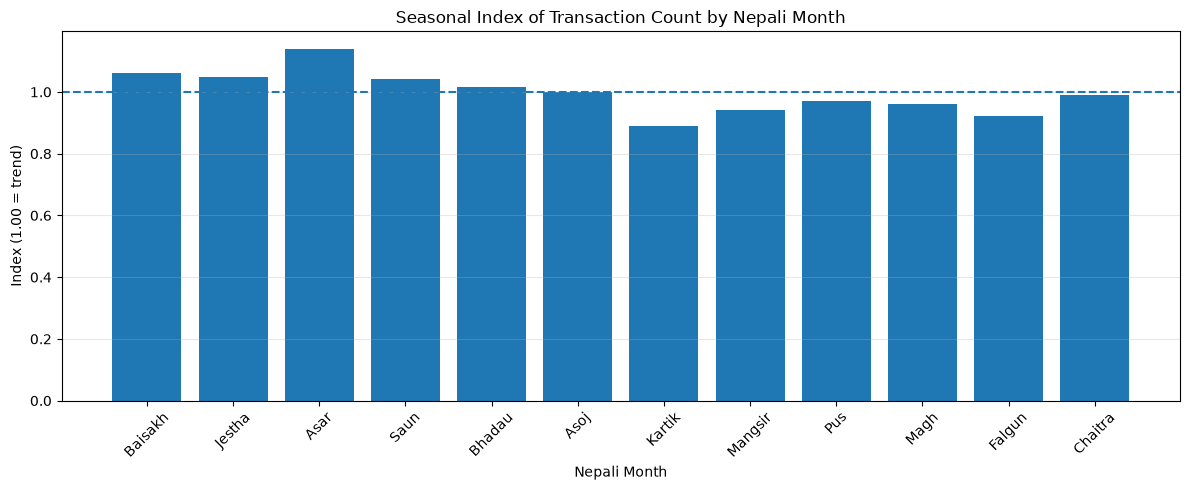

In [48]:
plt.figure(figsize=(12, 5))
plt.bar(seasonal_index_by_month.index.astype(str), seasonal_index_by_month.values)
plt.axhline(1, linestyle="--")
plt.title("Seasonal Index of Transaction Count by Nepali Month")
plt.xlabel("Nepali Month")
plt.ylabel("Index (1.00 = trend)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Key Observations – BS Month Seasonality
1. The raw monthly averages are not directly comparable. Each month has only 3 or 4 years of data, and transaction count grew strongly over time (for example, Jestha's average includes BS 2083 but Kartik's does not).
2. After removing the growth trend (seasonal index, where 1.00 = trend), Kartik is the weakest month for transaction count (about 0.89), followed by Falgun (about 0.92) and Mangsir (about 0.94). This is probably linked to the festival season.
3. Asar is the strongest month (about 1.14), followed by Baisakh (about 1.06) and Jestha (about 1.05).
4. Transaction amount follows a different pattern. Falgun is the weakest month, while Asar, Kartik and Saun are the strongest. Amount is dominated by RTGS, so it is more volatile than count.
5. Each month has only 3 to 4 observations, so these patterns are indicative, not firm.

### Average Monthly Transaction Count by Nepali Month

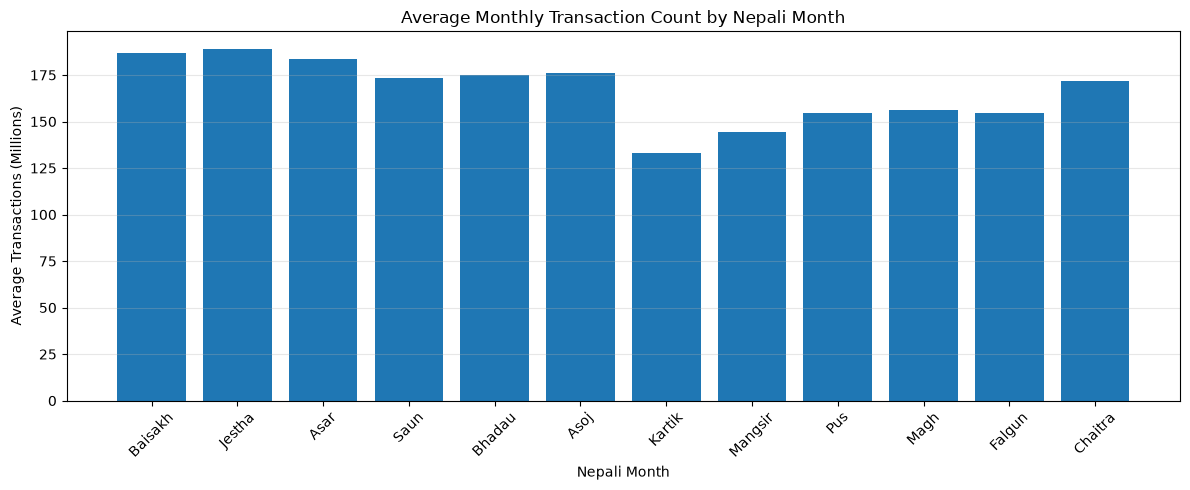

In [24]:
plt.figure(figsize=(12, 5))

plt.bar(
    bs_month_seasonality["bs_month"].astype(str),
    bs_month_seasonality["avg_txn_count"] / 1_000_000
)

plt.title("Average Monthly Transaction Count by Nepali Month")
plt.xlabel("Nepali Month")
plt.ylabel("Average Transactions (Millions)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Average Transaction Amount by Nepali Month

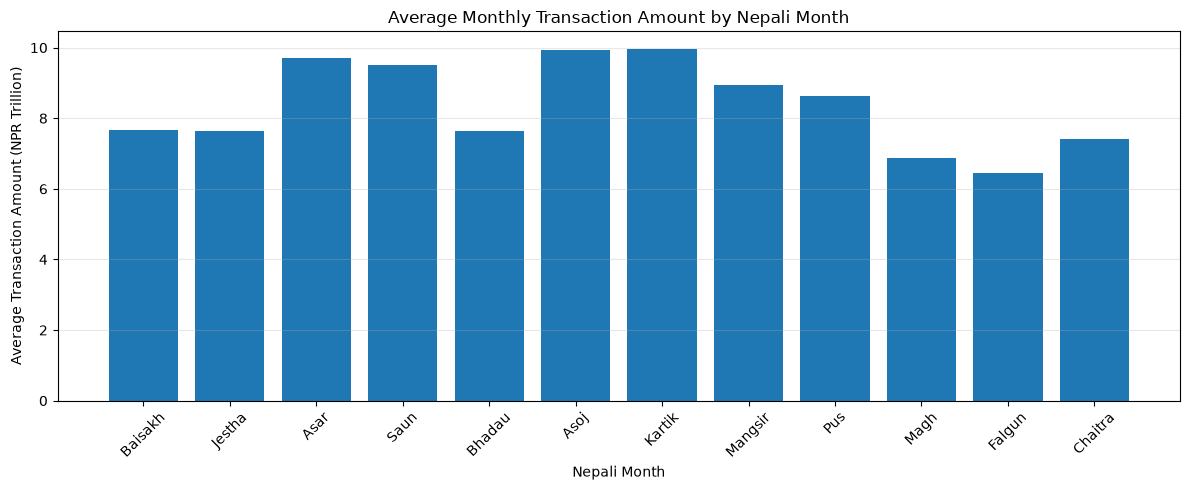

In [25]:
plt.figure(figsize=(12, 5))

plt.bar(
    bs_month_seasonality["bs_month"].astype(str),
    bs_month_seasonality["avg_txn_amount_npr_million"] / 1_000_000
)

plt.title("Average Monthly Transaction Amount by Nepali Month")
plt.xlabel("Nepali Month")
plt.ylabel("Average Transaction Amount (NPR Trillion)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Payment Instrument Contribution Trends

In [26]:
instrument_trends = (
    df.groupby("instrument")
    .agg(
        total_txn_count_million=("txn_count", "sum"),
        total_txn_amount_npr_million=("txn_amount_npr_million", "sum"),
        months_reported=("period_end", "nunique")
    )
    .reset_index()
)

instrument_trends["txn_count_share_pct"] = (
    instrument_trends["total_txn_count_million"]
    / instrument_trends["total_txn_count_million"].sum() * 100
)

instrument_trends["txn_amount_share_pct"] = (
    instrument_trends["total_txn_amount_npr_million"]
    / instrument_trends["total_txn_amount_npr_million"].sum() * 100
)

# Convert units for readability
instrument_trends["total_txn_count_million"] /= 1_000_000
instrument_trends["total_txn_amount_npr_trillion"] = (
    instrument_trends['total_txn_amount_npr_million'] / 1_000_000
)

instrument_trends = instrument_trends.drop(
    columns= "total_txn_amount_npr_million"
).sort_values("total_txn_amount_npr_trillion",ascending=False)

instrument_trends.style.format({
    "total_txn_count_million": "{:,.2f}",
    "total_txn_amount_npr_trillion": "{:,.2f}",
    "months_reported": "{:.0f}",
    "txn_count_share_pct": "{:.2f}%",
    "txn_amount_share_pct": "{:.2f}%"
})

,instrument,total_txn_count_million,months_reported,txn_count_share_pct,txn_amount_share_pct,total_txn_amount_npr_trillion
15,RTGS,2.78,40,0.04%,72.85%,246.25
6,ECC (Cheque Clearing),42.09,40,0.63%,6.29%,21.25
10,Mobile Banking,"2,116.46",40,31.56%,5.08%,17.16
11,Other Retail Payments,260.87,29,3.89%,4.44%,15.00
7,Faster Payment Systems,508.55,31,7.58%,4.42%,14.95
8,IPS,102.76,40,1.53%,2.98%,10.07
14,QR-Based Payments,"1,318.99",40,19.67%,1.07%,3.62
4,Debit Cards,445.05,40,6.64%,1.05%,3.54
0,ATM Cash Withdrawal,417.02,40,6.22%,1.01%,3.41
16,Wallet,"1,404.82",40,20.95%,0.46%,1.57


### Key Observations – Payment Instrument Contribution
1. Mobile Banking leads transaction volume, contributing 31.56% of total transactions.
2. Wallet and QR-Based Payments contribute 20.95% and 19.67% of transaction volume, respectively.
3. Mobile Banking, Wallet and QR collectively account for 72.18% of all transactions.
4. RTGS dominates transaction value, contributing 72.85% despite representing only 0.04% of transaction volume.
5. ECC contributes 6.29% of transaction value, while Faster Payment Systems contribute 4.42%.
6. Reporting coverage varies across instruments, which should be considered when comparing cumulative totals.

### Monthly Transaction Count

In [27]:
all_months = pd.date_range(
    start=df["period_end"].min(),
    end=df["period_end"].max(),
    freq="MS"
)

all_instruments = df["instrument"].unique()

instrument_monthly_count = (
    pd.MultiIndex.from_product(
        [all_months, all_instruments],
        names=["period_end", "instrument"]
    )
    .to_frame(index=False)
    .merge(
        df[["period_end", "instrument", "txn_count"]],
        on=["period_end", "instrument"],
        how="left"
    )
    .sort_values(["instrument", "period_end"])
    .reset_index(drop=True)
)

instrument_monthly_count.head(20)

,period_end,instrument,txn_count
0,2023-07-01,ATM Cash Withdrawal,11042117.0
1,2023-08-01,ATM Cash Withdrawal,10878681.0
2,2023-09-01,ATM Cash Withdrawal,11168727.0
3,2023-10-01,ATM Cash Withdrawal,11512710.0
4,2023-11-01,ATM Cash Withdrawal,10318787.0
5,2023-12-01,ATM Cash Withdrawal,9586546.0
6,2024-01-01,ATM Cash Withdrawal,10455659.0
7,2024-02-01,ATM Cash Withdrawal,10711574.0
8,2024-03-01,ATM Cash Withdrawal,10785143.0
9,2024-04-01,ATM Cash Withdrawal,10975001.0


In [28]:
instrument_monthly_count["txn_count_mom_growth_pct"] = (
    instrument_monthly_count
    .groupby("instrument")["txn_count"]
    .pct_change(fill_method=None) * 100
).round(2)

instrument_monthly_count.head(5)

,period_end,instrument,txn_count,txn_count_mom_growth_pct
0,2023-07-01,ATM Cash Withdrawal,11042117.0,NaN
1,2023-08-01,ATM Cash Withdrawal,10878681.0,-1.48
2,2023-09-01,ATM Cash Withdrawal,11168727.0,2.67
3,2023-10-01,ATM Cash Withdrawal,11512710.0,3.08
4,2023-11-01,ATM Cash Withdrawal,10318787.0,-10.37


In [29]:
instrument_growth_summary = (
    instrument_monthly_count
    .groupby("instrument")
    .agg(
        highest_mom_growth_pct=("txn_count_mom_growth_pct", "max"),
        lowest_mom_growth_pct=("txn_count_mom_growth_pct", "min"),
        avg_mom_growth_pct=("txn_count_mom_growth_pct", "mean")
    )
    .reset_index()
    .sort_values("avg_mom_growth_pct", ascending=False)
)

instrument_growth_summary.round(2)

,instrument,highest_mom_growth_pct,lowest_mom_growth_pct,avg_mom_growth_pct
8,IPS,342.50,-86.42,44.79
3,Cross Border QR Acquiring,66.63,-25.28,10.87
14,QR-Based Payments,28.89,-26.53,5.90
11,Other Retail Payments,33.05,-23.22,4.17
5,E-Commerce (card-based),32.46,-30.19,3.88
13,Prepaid Cards,18.59,-16.82,2.75
16,Wallet,16.72,-7.07,2.68
7,Faster Payment Systems,13.87,-11.42,2.65
10,Mobile Banking,20.70,-18.75,2.48
6,ECC (Cheque Clearing),39.53,-38.69,1.91


### Monthly transaction amounts

In [30]:
instrument_monthly_amount=(
    df[
        ["period_end","instrument","txn_amount_npr_million"]
    ]
    .copy()
    .sort_values(["instrument","period_end"])
    .reset_index(drop=True)
)
instrument_monthly_amount.head(15)

,period_end,instrument,txn_amount_npr_million
0,2023-07-01,ATM Cash Withdrawal,86964
1,2023-08-01,ATM Cash Withdrawal,81383
2,2023-09-01,ATM Cash Withdrawal,83384
3,2023-10-01,ATM Cash Withdrawal,96054
4,2023-11-01,ATM Cash Withdrawal,92401
5,2023-12-01,ATM Cash Withdrawal,80101
6,2024-01-01,ATM Cash Withdrawal,84422
7,2024-02-01,ATM Cash Withdrawal,86485
8,2024-03-01,ATM Cash Withdrawal,88070
9,2024-04-01,ATM Cash Withdrawal,89874


In [31]:
instrument_monthly_amount = (
    pd.MultiIndex.from_product(
        [all_months, all_instruments],
        names=["period_end", "instrument"]
    )
    .to_frame(index=False)
    .merge(
        instrument_monthly_amount,
        on=["period_end", "instrument"],
        how="left"
    )
    .sort_values(["instrument", "period_end"])
    .reset_index(drop=True)
)
instrument_monthly_amount.head(20)

,period_end,instrument,txn_amount_npr_million
0,2023-07-01,ATM Cash Withdrawal,86964.0
1,2023-08-01,ATM Cash Withdrawal,81383.0
2,2023-09-01,ATM Cash Withdrawal,83384.0
3,2023-10-01,ATM Cash Withdrawal,96054.0
4,2023-11-01,ATM Cash Withdrawal,92401.0
5,2023-12-01,ATM Cash Withdrawal,80101.0
6,2024-01-01,ATM Cash Withdrawal,84422.0
7,2024-02-01,ATM Cash Withdrawal,86485.0
8,2024-03-01,ATM Cash Withdrawal,88070.0
9,2024-04-01,ATM Cash Withdrawal,89874.0


### month-over-month amount growth

In [32]:
instrument_monthly_amount["txn_amount_mom_growth_pct"] = (
    instrument_monthly_amount
    .groupby("instrument")["txn_amount_npr_million"]
    .pct_change(fill_method=None) * 100
)
instrument_monthly_amount["txn_amount_mom_growth_pct"] = (
    instrument_monthly_amount["txn_amount_mom_growth_pct"].round(2)
)
instrument_monthly_amount.head(20)

,period_end,instrument,txn_amount_npr_million,txn_amount_mom_growth_pct
0,2023-07-01,ATM Cash Withdrawal,86964.0,NaN
1,2023-08-01,ATM Cash Withdrawal,81383.0,-6.42
2,2023-09-01,ATM Cash Withdrawal,83384.0,2.46
3,2023-10-01,ATM Cash Withdrawal,96054.0,15.19
4,2023-11-01,ATM Cash Withdrawal,92401.0,-3.80
5,2023-12-01,ATM Cash Withdrawal,80101.0,-13.31
6,2024-01-01,ATM Cash Withdrawal,84422.0,5.39
7,2024-02-01,ATM Cash Withdrawal,86485.0,2.44
8,2024-03-01,ATM Cash Withdrawal,88070.0,1.83
9,2024-04-01,ATM Cash Withdrawal,89874.0,2.05


### Summarize amount growth by instrument

In [33]:
instrument_amount_growth_summary = (
    instrument_monthly_amount
    .groupby("instrument")
    .agg(
        highest_mom_growth_pct=("txn_amount_mom_growth_pct", "max"),
        lowest_mom_growth_pct=("txn_amount_mom_growth_pct", "min"),
        avg_mom_growth_pct=("txn_amount_mom_growth_pct", "mean")
    )
    .reset_index()
    .sort_values("avg_mom_growth_pct", ascending=False)
)

instrument_amount_growth_summary.round(2)

,instrument,highest_mom_growth_pct,lowest_mom_growth_pct,avg_mom_growth_pct
3,Cross Border QR Acquiring,70.75,-28.10,10.86
8,IPS,103.48,-64.54,8.10
15,RTGS,86.37,-40.64,6.45
11,Other Retail Payments,52.99,-46.43,6.31
14,QR-Based Payments,23.59,-13.42,5.54
13,Prepaid Cards,36.41,-39.57,4.47
5,E-Commerce (card-based),33.49,-32.72,4.34
16,Wallet,29.96,-16.28,2.96
10,Mobile Banking,17.25,-18.66,2.87
7,Faster Payment Systems,21.66,-19.14,2.86


### Compare count growth vs amount growth

In [34]:
instrument_growth_comparison = (
    instrument_growth_summary[
        ["instrument", "avg_mom_growth_pct"]
    ]
    .merge(
        instrument_amount_growth_summary[
            ["instrument", "avg_mom_growth_pct"]
        ],
        on="instrument",
        suffixes=("_count", "_amount")
    )
    .sort_values("avg_mom_growth_pct_count", ascending=False)
)

instrument_growth_comparison.round(2)

,instrument,avg_mom_growth_pct_count,avg_mom_growth_pct_amount
0,IPS,44.79,8.10
1,Cross Border QR Acquiring,10.87,10.86
2,QR-Based Payments,5.90,5.54
3,Other Retail Payments,4.17,6.31
4,E-Commerce (card-based),3.88,4.34
5,Prepaid Cards,2.75,4.47
6,Wallet,2.68,2.96
7,Faster Payment Systems,2.65,2.86
8,Mobile Banking,2.48,2.87
9,ECC (Cheque Clearing),1.91,2.34


### Key Observations
1. IPS had the highest average monthly transaction count growth (44.79%), but this is inflated by a few one-off count spikes (max +342% in a single month), so it should not be read as steady growth.
2. Cross Border QR Acquiring had the next highest count growth (10.87%) and the highest average transaction amount growth (10.86%). It only started reporting in Oct 2024, so this reflects its early ramp-up.
3. QR-Based Payments showed strong growth in both count (5.90%) and amount (5.54%).
4. RTGS had modest count growth (1.40%) but higher amount growth (6.45%), meaning the value per transaction is rising.
5. ATM Cash Withdrawal (-0.28%), Point of Sales (-0.28%) and Debit Cards (-0.32%) were the only instruments with negative average count growth.
6. Wallet (2.68%) and Mobile Banking (2.48%) grew steadily at a similar pace.

Note: These are averages of month-on-month % changes. They are sensitive to spikes and to months with missing reports, so they are best used for comparison, not as exact growth rates.

### Top 5 instruments in each year

In [35]:
yearly_instrument_count = (
    df.groupby(["bs_year", "instrument"])
    .agg(
        total_txn_count=("txn_count", "sum"),
        months_reported=("period_end", "nunique")
    )
    .reset_index()
)

yearly_instrument_count["txn_count_million"] = (
    yearly_instrument_count["total_txn_count"] / 1_000_000
)

yearly_instrument_count

,bs_year,instrument,total_txn_count,months_reported,txn_count_million
0,2080,ATM Cash Withdrawal,107434945,10,107.434945
1,2080,Branchless Banking,707643,10,0.707643
2,2080,Credit Cards,2651939,10,2.651939
3,2080,Debit Cards,115074175,10,115.074175
4,2080,E-Commerce (card-based),1144491,10,1.144491
...,...,...,...,...,...
62,2083,Point of Sales (POS),4767615,6,4.767615
63,2083,Prepaid Cards,914246,6,0.914246
64,2083,QR-Based Payments,418638584,6,418.638584
65,2083,RTGS,443995,6,0.443995


In [36]:
yearly_top_5_count = (
    yearly_instrument_count
    .sort_values(
        ["bs_year", "total_txn_count"],
        ascending=[True, False]
    )
    .groupby("bs_year")
    .head(5)
    .sort_values(
        ["bs_year", "total_txn_count"],
        ascending=[True, False]
    )
)

yearly_top_5_count[
    ["bs_year", "instrument", "txn_count_million", "months_reported"]
]

,bs_year,instrument,txn_count_million,months_reported
9,2080,Mobile Banking,320.465733,10
15,2080,Wallet,222.889343,10
13,2080,QR-Based Payments,120.827283,10
3,2080,Debit Cards,115.074175,10
0,2080,ATM Cash Withdrawal,107.434945,10
26,2081,Mobile Banking,565.970544,12
32,2081,Wallet,377.728272,12
30,2081,QR-Based Payments,275.120630,12
23,2081,Faster Payment Systems,160.813330,12
20,2081,Debit Cards,140.662154,12


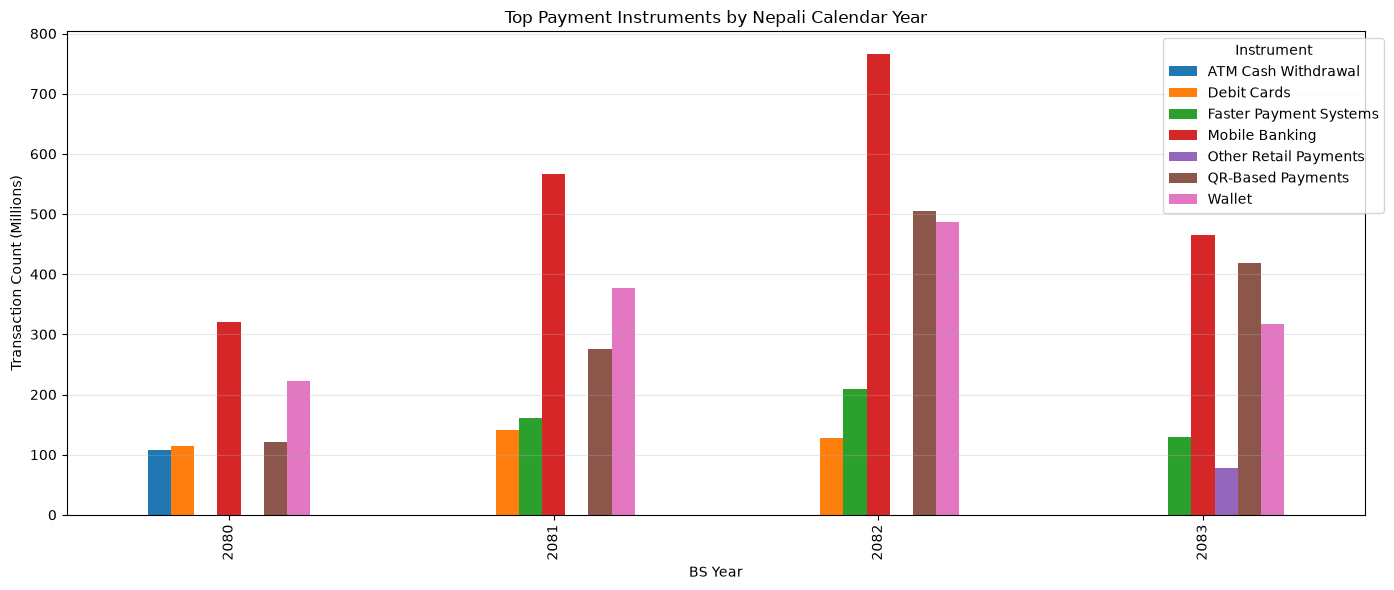

In [37]:
yearly_top_5_count.pivot(
    index="bs_year",
    columns="instrument",
    values="txn_count_million"
).plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Top Payment Instruments by Nepali Calendar Year")
plt.xlabel("BS Year")
plt.ylabel("Transaction Count (Millions)")
plt.legend(title="Instrument", bbox_to_anchor=(1.02, 1))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Key observations 
1. Mobile Banking remained the number one instrument across all four years.
2. QR-Based Payments grew significantly and ranked second in 2082 and 2083.
3. Wallet ranked second in 2080 and 2081 but dropped to third in 2082 and 2083.
4. Faster Payment Systems entered the top five from 2081.
5. 2083 contains only 6 months of data, so its totals shouldn't be directly compared with full-year totals.

### Year-wise transaction amount by payment instrument.

In [38]:
yearly_instrument_amount = (
    df.groupby(["bs_year", "instrument"])
    .agg(
        total_txn_amount_npr_million=("txn_amount_npr_million", "sum"),
        months_reported=("period_end", "nunique")
    )
    .reset_index()
)

yearly_instrument_amount["txn_amount_npr_billion"] = (
    yearly_instrument_amount["total_txn_amount_npr_million"] / 1000
)

yearly_instrument_amount

,bs_year,instrument,total_txn_amount_npr_million,months_reported,txn_amount_npr_billion
0,2080,ATM Cash Withdrawal,869138,10,869.138
1,2080,Branchless Banking,14819,10,14.819
2,2080,Credit Cards,17556,10,17.556
3,2080,Debit Cards,903770,10,903.770
4,2080,E-Commerce (card-based),6882,10,6.882
...,...,...,...,...,...
62,2083,Point of Sales (POS),24726,6,24.726
63,2083,Prepaid Cards,7762,6,7.762
64,2083,QR-Based Payments,1055523,6,1055.523
65,2083,RTGS,38471726,6,38471.726


In [39]:
yearly_top_5_amount = (
    yearly_instrument_amount
    .sort_values(
        ["bs_year", "total_txn_amount_npr_million"],
        ascending=[True, False]
    )
    .groupby("bs_year")
    .head(5)
    .sort_values(
        ["bs_year", "total_txn_amount_npr_million"],
        ascending=[True, False]
    )
)

yearly_top_5_amount[
    ["bs_year", "instrument", "txn_amount_npr_billion", "months_reported"]
]

,bs_year,instrument,txn_amount_npr_billion,months_reported
14,2080,RTGS,28011.680,10
5,2080,ECC (Cheque Clearing),4928.454,10
9,2080,Mobile Banking,2650.791,10
7,2080,IPS,1942.628,10
3,2080,Debit Cards,903.770,10
31,2081,RTGS,66824.760,12
22,2081,ECC (Cheque Clearing),6124.215,12
23,2081,Faster Payment Systems,4913.592,12
26,2081,Mobile Banking,4640.131,12
27,2081,Other Retail Payments,3978.027,10


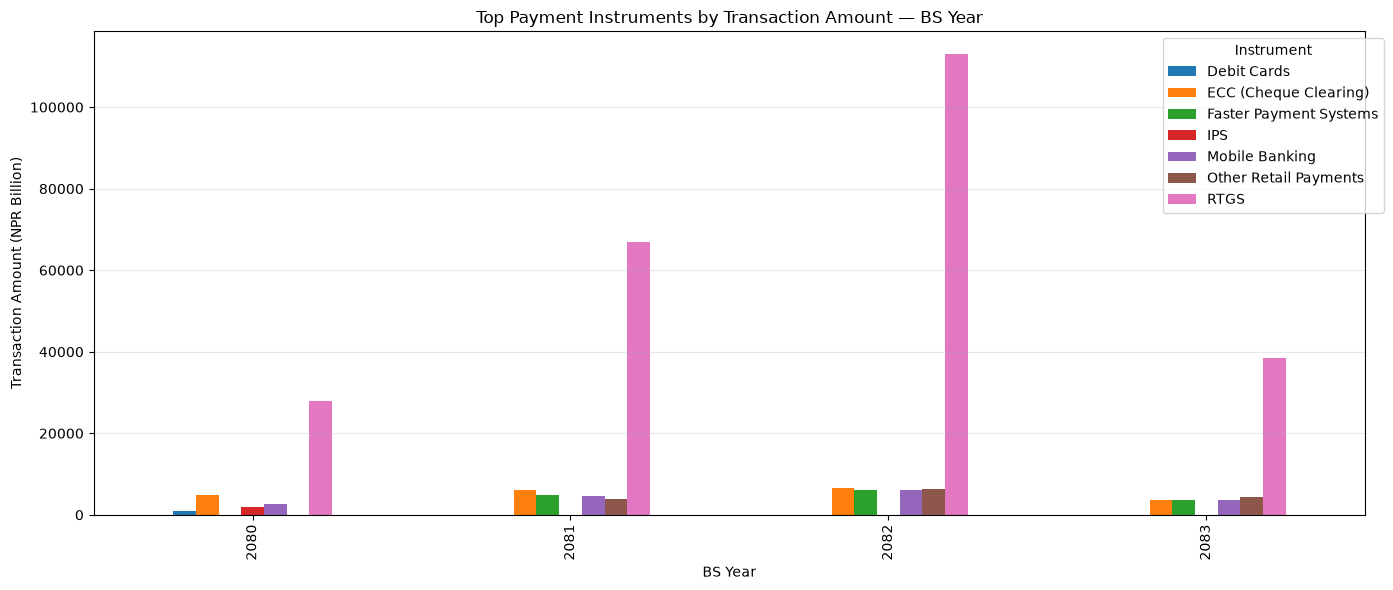

In [40]:
yearly_top_5_amount.pivot(
    index="bs_year",
    columns="instrument",
    values="txn_amount_npr_billion"
).plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Top Payment Instruments by Transaction Amount — BS Year")
plt.xlabel("BS Year")
plt.ylabel("Transaction Amount (NPR Billion)")
plt.legend(title="Instrument", bbox_to_anchor=(1.02, 1))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Key Observations
1. RTGS dominated transaction value in every year, reaching NPR 112,943.94 billion in 2082.
2. ECC (Cheque Clearing) consistently ranked among the top two, showing its importance in high-value payments.
3. Mobile Banking remained in the top five across all four years.
4. Faster Payment Systems entered the top five in 2081 and maintained its position afterward.
5. Other Retail Payments became a major contributor from 2081 onward.
6. 2083 covers only six months, so its total transaction amounts are not directly comparable with full-year totals.

Important insight: Transaction count and transaction amount tell different stories. Digital channels dominate transaction volume, while RTGS dominates transaction value.

### Average Yearly Transaction by instrument


In [41]:
yearly_avg_txn_value = (
    df.groupby(["bs_year", "instrument"])
    .agg(
        total_txn_count=("txn_count", "sum"),
        total_txn_amount_npr_million=("txn_amount_npr_million", "sum")
    )
    .reset_index()
)

yearly_avg_txn_value["avg_txn_value_npr"] = (
    yearly_avg_txn_value["total_txn_amount_npr_million"]
    * 1_000_000
    / yearly_avg_txn_value["total_txn_count"]
).round(2)

yearly_avg_txn_value

,bs_year,instrument,total_txn_count,total_txn_amount_npr_million,avg_txn_value_npr
0,2080,ATM Cash Withdrawal,107434945,869138,8089.90
1,2080,Branchless Banking,707643,14819,20941.35
2,2080,Credit Cards,2651939,17556,6620.06
3,2080,Debit Cards,115074175,903770,7853.80
4,2080,E-Commerce (card-based),1144491,6882,6013.15
...,...,...,...,...,...
62,2083,Point of Sales (POS),4767615,24726,5186.24
63,2083,Prepaid Cards,914246,7762,8490.06
64,2083,QR-Based Payments,418638584,1055523,2521.32
65,2083,RTGS,443995,38471726,86649007.31


In [42]:
yearly_avg_txn_ranking = (
    yearly_avg_txn_value
    .sort_values(
        ["bs_year", "avg_txn_value_npr"],
        ascending=[True, False]
    )
    .groupby("bs_year")
    .head(5)
    .reset_index(drop=True)
)

yearly_avg_txn_ranking[
    ["bs_year", "instrument", "avg_txn_value_npr"]
].style.format({
    "avg_txn_value_npr": "{:,.2f}"
})

,bs_year,instrument,avg_txn_value_npr
0,2080,RTGS,"42,571,136.34"
1,2080,ECC (Cheque Clearing),"499,280.07"
2,2080,IPS,"100,224.84"
3,2080,Other Retail Payments,"87,385.66"
4,2080,Internet Banking,"48,086.38"
5,2081,RTGS,"79,934,401.52"
6,2081,ECC (Cheque Clearing),"495,843.89"
7,2081,IPS,"89,674.32"
8,2081,Other Retail Payments,"58,428.38"
9,2081,Internet Banking,"48,540.70"


### Key Observations
1. RTGS had the highest average transaction value in every year, reaching approximately NPR 133.60 million in 2082.
2. ECC (Cheque Clearing) consistently ranked second, averaging around NPR 0.5 million per transaction.
3. IPS ranked third in all four years.
4. RTGS average transaction value increased significantly from NPR 42.57 million in 2080 to NPR 133.60 million in 2082.
5. The ranking remained largely consistent across all four years.

Key insight: RTGS and cheque clearing handle much higher-value transactions, while digital retail channels generally handle smaller individual transactions.

### top 5 payment instruments by transaction count(overall)

In [43]:
top_5_instruments = (
    instrument_trends
    .nlargest(5, "txn_count_share_pct")["instrument"]
)

top_5_monthly = instrument_monthly_count[
    instrument_monthly_count["instrument"].isin(top_5_instruments)
].copy()

top_5_monthly["txn_count_million"] = (
    top_5_monthly["txn_count"] / 1_000_000
)

count_trend_pivot = top_5_monthly.pivot(
    index="period_end",
    columns="instrument",
    values="txn_count_million"
)
count_trend_pivot

instrument,Debit Cards,Faster Payment Systems,Mobile Banking,QR-Based Payments,Wallet
period_end,,,,,
2023-07-01,11.838532,9.783842,28.903872,9.766216,20.822861
2023-08-01,11.609914,NaN,31.281546,11.257388,22.205947
2023-09-01,11.889616,NaN,34.493252,11.799175,22.414576
2023-10-01,12.340969,NaN,32.772839,11.883100,22.622170
2023-11-01,11.158905,NaN,26.981617,8.729939,21.130619
2023-12-01,10.320773,NaN,31.327659,11.252394,22.683040
2024-01-01,11.222577,NaN,33.224078,12.586268,21.388368
2024-02-01,11.417089,NaN,33.852704,13.157762,22.727369
2024-03-01,11.523192,NaN,32.462954,14.291877,22.410321


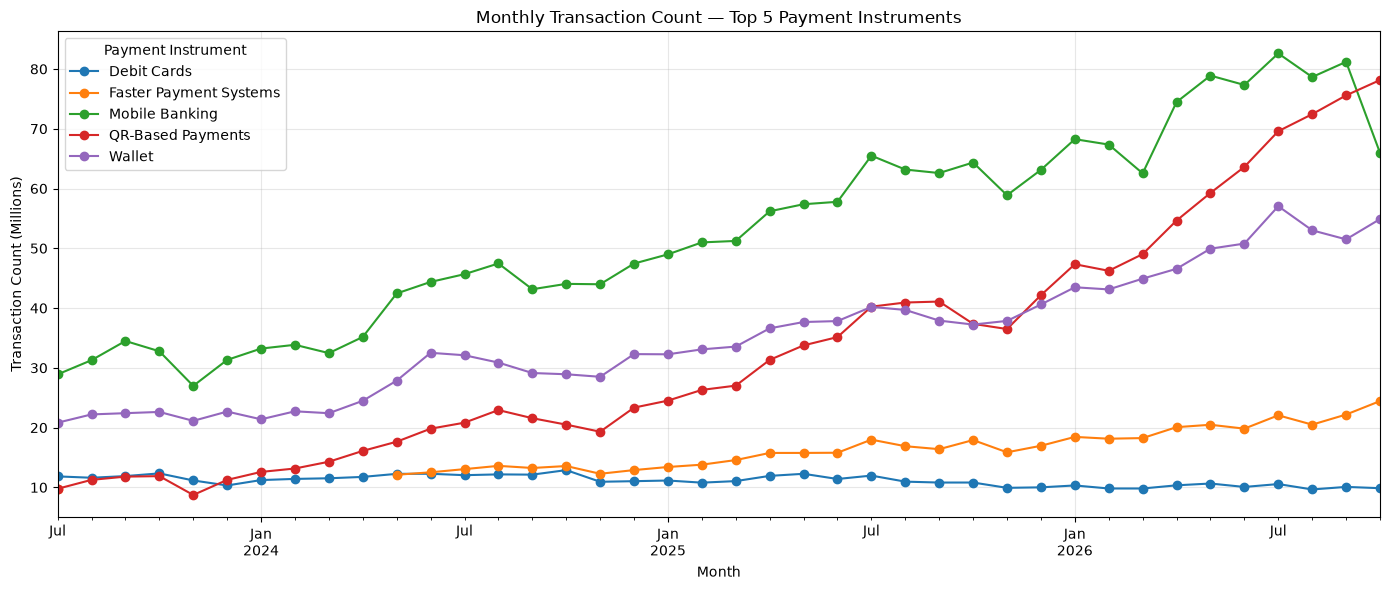

In [44]:
import matplotlib.pyplot as plt

count_trend_pivot.plot(
    figsize=(14, 6),
    marker="o"
)

plt.title("Monthly Transaction Count — Top 5 Payment Instruments")
plt.xlabel("Month")
plt.ylabel("Transaction Count (Millions)")
plt.legend(title="Payment Instrument")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### monthly transaction amount trends for the same top 5 instruments

In [45]:
top_5_monthly_amount = instrument_monthly_amount[
    instrument_monthly_amount["instrument"].isin(top_5_instruments)
].copy()

top_5_monthly_amount["txn_amount_npr_billion"] = (
    top_5_monthly_amount["txn_amount_npr_million"] / 1000
)

amount_trend_pivot = top_5_monthly_amount.pivot(
    index="period_end",
    columns="instrument",
    values="txn_amount_npr_billion"
)

amount_trend_pivot

instrument,Debit Cards,Faster Payment Systems,Mobile Banking,QR-Based Payments,Wallet
period_end,,,,,
2023-07-01,90.541,321.519,233.446,30.148,20.326
2023-08-01,84.306,NaN,242.915,29.996,21.916
2023-09-01,86.149,NaN,242.261,30.564,21.092
2023-10-01,100.110,NaN,277.824,36.215,22.796
2023-11-01,96.092,NaN,228.328,32.017,20.246
2023-12-01,83.721,NaN,263.464,38.060,23.181
2024-01-01,88.070,NaN,282.241,38.596,23.084
2024-02-01,89.744,NaN,289.387,37.734,23.872
2024-03-01,91.480,NaN,291.954,42.560,24.020


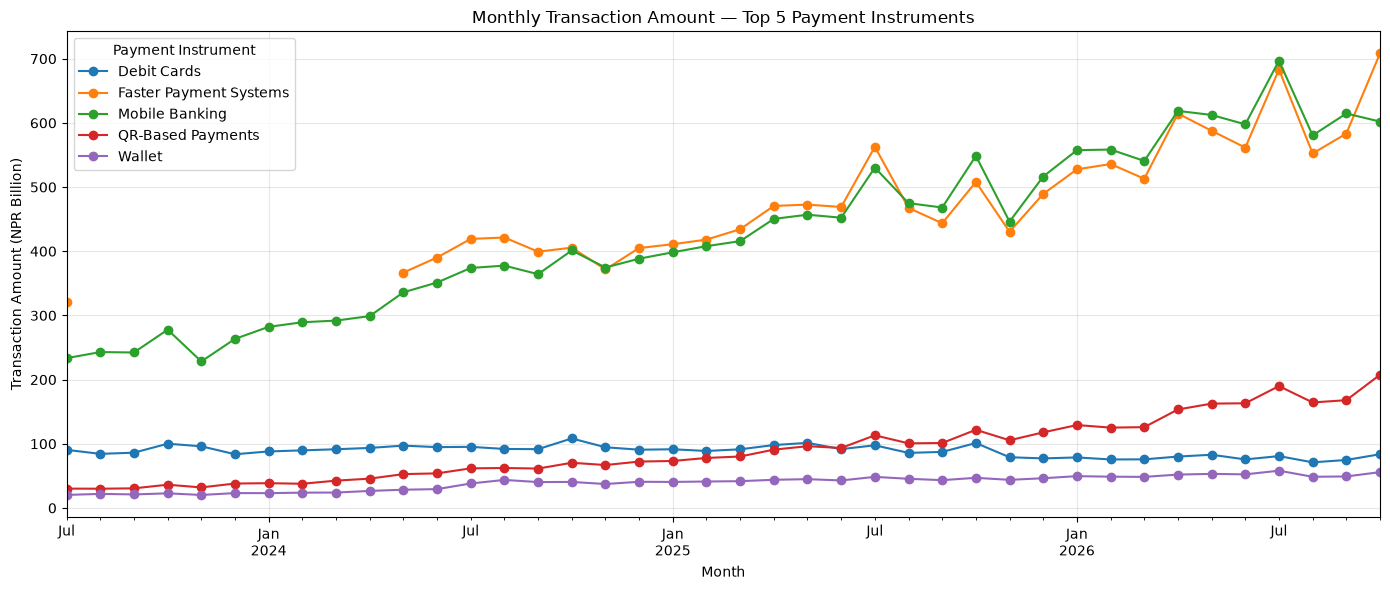

In [46]:
amount_trend_pivot.plot(
    figsize=(14, 6),
    marker="o"
)

plt.title("Monthly Transaction Amount — Top 5 Payment Instruments")
plt.xlabel("Month")
plt.ylabel("Transaction Amount (NPR Billion)")
plt.legend(title="Payment Instrument")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Key findings
1. Transaction growth: Overall digital payment transaction volume increased over the analysis period.
2. Leading instruments: Mobile Banking, Wallet and QR-Based Payments contributed the majority of transaction counts.
3. Transaction value: RTGS dominated total transaction amount despite having a very small share of transaction count.
4. Year-wise trends: QR-Based Payments gained prominence in transaction volume, while Faster Payment Systems entered the top five.
5. Average transaction value: RTGS consistently recorded the highest average transaction value, followed by ECC.
6. Seasonality: Monthly transaction counts and amounts showed different seasonal patterns.
7. Data coverage: Some instruments have missing reporting months, and BS 2083 contains only six months in our dataset.
